In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("airline-passengers.csv")

In [3]:
df.head()

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [4]:
df.shape

(144, 2)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Month       144 non-null    str  
 1   Passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 3.4 KB


In [6]:
df['Month'] = pd.to_datetime(df['Month'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       144 non-null    datetime64[us]
 1   Passengers  144 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 2.4 KB


<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">

در این قسمت می‌بینیم که نوع داده‌های ستون
<bdi dir="ltr">Month</bdi>
از نوع
<bdi dir="ltr">str</bdi>
است؛ درحالی‌که برای انجام تحلیل‌های زمانی، لازم است تاریخ‌ها به فرمت واقعی تاریخ تبدیل شوند. به همین دلیل، این ستون را به نوع
<bdi dir="ltr">datetime</bdi>
تبدیل می‌کنیم.

</div>

In [17]:
df = pd.read_csv("airline-passengers.csv")
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

In [20]:
df.index


DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[us]', name='Month', length=144, freq=None)

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">

در مرحله بعد، ایندکس‌های عددی رو حذف می‌کنیم و ستون <bdi dir="ltr">Month</bdi> رو به‌عنوان <bdi dir="ltr">Index</bdi> قرار می‌دیم؛ چون در تحلیل سری‌های زمانی بهتره تاریخ‌ها به‌عنوان ایندکس استفاده بشن. از اونجایی که در این دستور از <bdi dir="ltr">inplace=True</bdi> استفاده می‌کنیم، تغییر مستقیماً روی دیتاست اعمال می‌شه. بنابراین، برای اینکه هنگام اجرای مجدد کل نوت‌بوک با خطا مواجه نشیم، دیتاست رو قبل از این مرحله دوباره بارگذاری می‌کنیم.

</div>

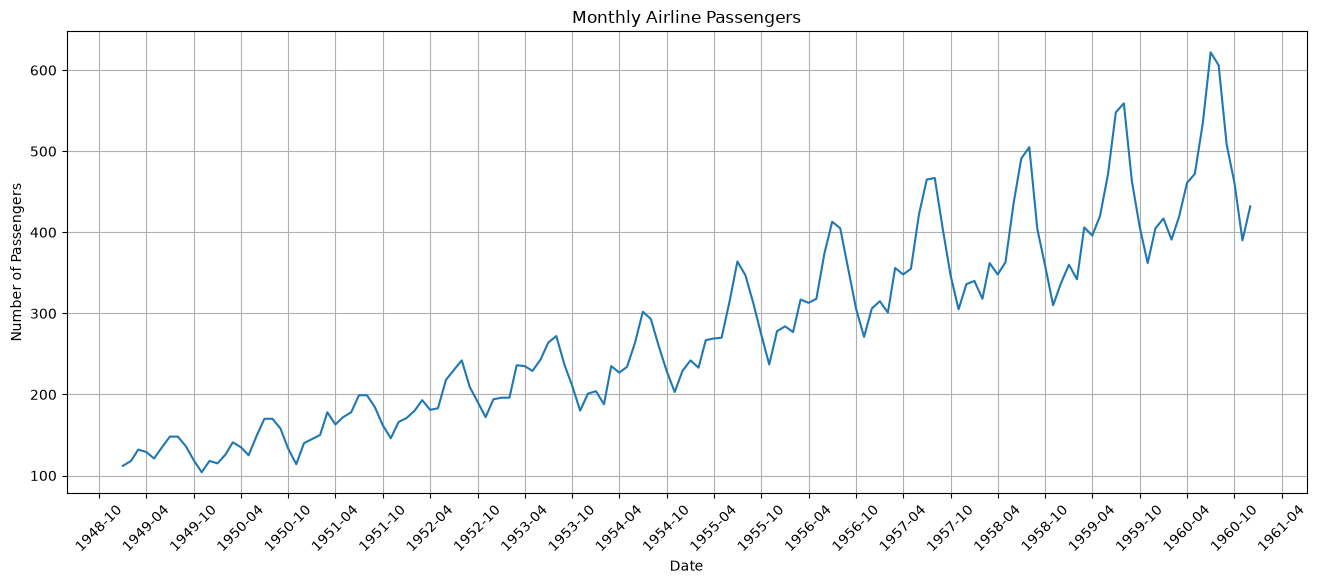

In [22]:
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

plt.plot(df.index, df['Passengers'])

plt.title('Monthly Airline Passengers')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')

plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

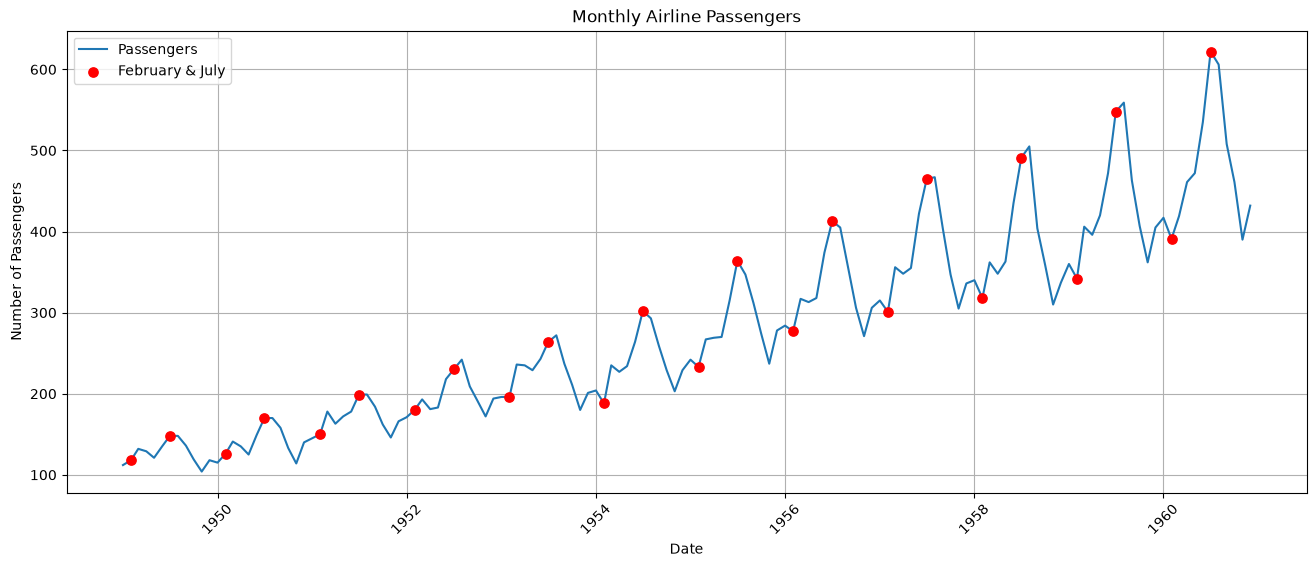

In [23]:
plt.figure(figsize=(16, 6))

# رسم نمودار اصلی
plt.plot(df.index, df['Passengers'], label='Passengers')

# مشخص کردن نقاط ماه فوریه و جولای
selected_months = df.index.month.isin([2, 7])

plt.scatter(
    df.index[selected_months],
    df['Passengers'][selected_months],
    color='red',
    s=45,
    label='February & July',
    zorder=3
)

plt.title('Monthly Airline Passengers')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()


<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این مرحله نمودار <bdi dir="ltr">Line Plot</bdi> رو رسم می‌کنیم تا روند کلی تغییرات تعداد مسافران و الگوهای تکرارشونده رو بررسی کنیم. همون‌طور که در نمودار می‌بینیم، تعداد مسافران در طول این سال‌ها به‌طور کلی افزایش پیدا کرده که با توجه به پیشرفت تکنولوژی و افزایش تعداد هواپیماها، منطقی به نظر می‌رسه.

همچنین می‌بینیم که معمولاً در ماه ۷ (جولای) بیشترین تعداد مسافران رو داریم و در ماه ۲ (فوریه) تعداد مسافران به کمترین مقدار خودش می‌رسه. از اونجایی که این افزایش و کاهش تقریباً هر سال در ماه‌های مشخصی تکرار می‌شه، می‌تونیم بگیم که داده‌ها دارای یک الگوی فصلی (<bdi dir="ltr">Seasonality</bdi>) هستن.
</div>


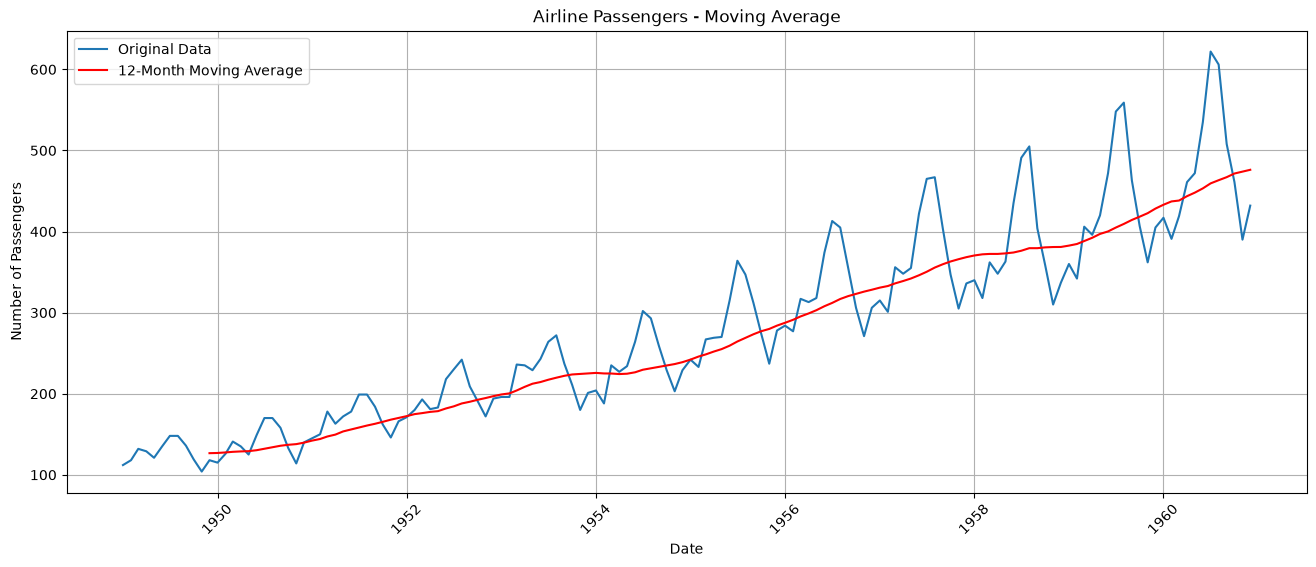

In [24]:
df['Moving_Average'] = df['Passengers'].rolling(window=12).mean()

plt.figure(figsize=(16, 6))

plt.plot(df.index, df['Passengers'], label='Original Data')
plt.plot(df.index, df['Moving_Average'], color='red', label='12-Month Moving Average')

plt.title('Airline Passengers - Moving Average')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()


<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این سلول نمودار خطی رو رسم می‌کنیم تا روند کلی داده‌ها رو با استفاده از <bdi dir="ltr">Moving Average</bdi> بررسی کنیم. در واقع، میانگین متحرک باعث می‌شه نمودار هموارتر بشه و به‌جای اینکه مقدار هر ماه رو به‌صورت جداگانه بررسی کنیم، میانگین مقادیر ۱۲ ماه متوالی رو در نظر بگیریم. همون‌طور که در نمودار می‌بینیم، با استفاده از این روش هم می‌تونیم روند صعودی تعداد مسافران رو در طول سال‌ها به‌وضوح مشاهده کنیم.
</div>


In [25]:
df['Month_Number'] = df.index.month

monthly_avg = df.groupby('Month_Number')['Passengers'].mean()

monthly_avg

Month_Number
1     241.750000
2     235.000000
3     270.166667
4     267.083333
5     271.833333
6     311.666667
7     351.333333
8     351.083333
9     302.416667
10    266.583333
11    232.833333
12    261.833333
Name: Passengers, dtype: float64

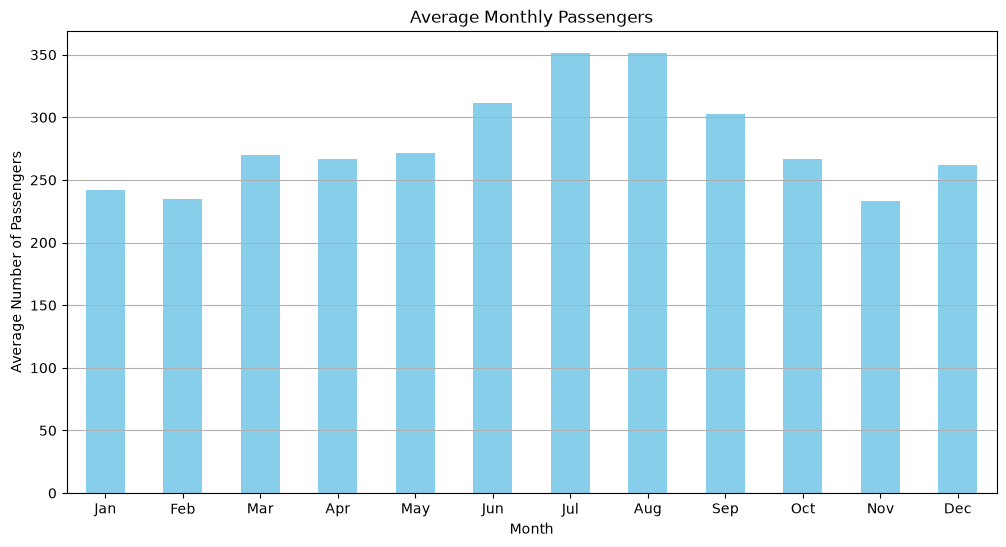

In [26]:
plt.figure(figsize=(12, 6))

monthly_avg.plot(kind='bar', color='skyblue')

plt.title('Average Monthly Passengers')
plt.xlabel('Month')
plt.ylabel('Average Number of Passengers')

plt.xticks(
    ticks=range(12),
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    rotation=0
)

plt.grid(axis='y')
plt.show()


<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
ابتدا میانگین تعداد مسافران رو در هر ماه محاسبه می‌کنیم و برای مقایسه بهتر، نمودار میله‌ای اون رو رسم می‌کنیم. همون‌طور که در نمودار می‌بینیم، در ماه‌های آگوست و جولای بیشترین میانگین تعداد مسافران و در ماه‌های نوامبر و فوریه کمترین میانگین رو داریم.

از این موضوع می‌تونیم متوجه بشیم که معمولاً در فصل تابستون تعداد سفرها بیشتره و به‌طور کلی با گرم‌تر شدن هوا تعداد مسافران افزایش پیدا می‌کنه و با سردتر شدن هوا کاهش پیدا می‌کنه. این موضوع نشون‌دهنده وجود یک الگوی فصلی در تعداد مسافران هست.
</div>


In [27]:
from statsmodels.tsa.seasonal import seasonal_decompose

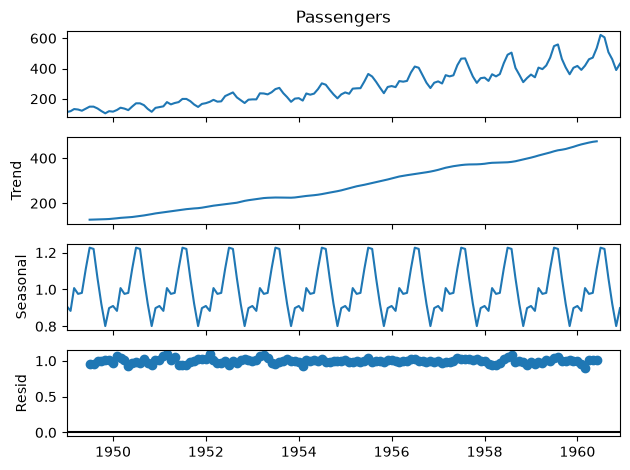

In [28]:
decomposition = seasonal_decompose(
    df['Passengers'],
    model='multiplicative',
    period=12
)

decomposition.plot()
plt.show()

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این مرحله با استفاده از روش <bdi dir="ltr">Time Series Decomposition</bdi> سری زمانی رو به بخش‌های مختلف تقسیم می‌کنیم. همون‌طور که در نمودار می‌بینیم، تعداد مسافران به‌صورت کلی روندی صعودی داره و یک الگوی فصلی مشخص هم در داده‌ها وجود داره. همچنین در نمودار <bdi dir="ltr">Residual</bdi> می‌بینیم که مقادیر باقی‌مانده تقریباً حول عدد ۱ قرار دارن. از اونجایی که در مدل ضربی رابطه به‌صورت <bdi dir="ltr">Y = T × S × R</bdi> هست، می‌تونیم نتیجه بگیریم که روند کلی و الگوی فصلی بخش زیادی از تغییرات تعداد مسافران رو توضیح می‌دن و تغییرات باقی‌مانده نسبتاً کمه.
</div>

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

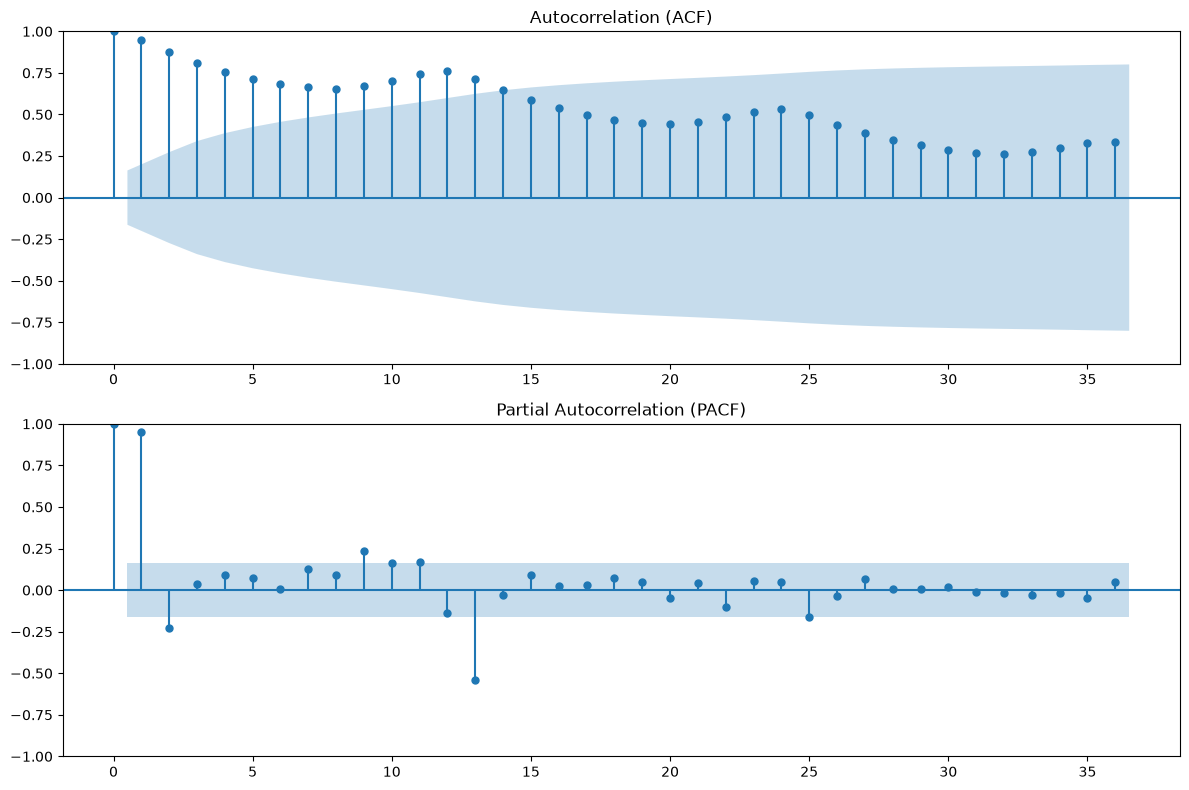

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df['Passengers'], lags=36, ax=axes[0])
axes[0].set_title('Autocorrelation (ACF)')

plot_pacf(df['Passengers'], lags=36, ax=axes[1], method='ywm')
axes[1].set_title('Partial Autocorrelation (PACF)')

plt.tight_layout()
plt.show()

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این مرحله میایم نمودارهای <bdi dir="ltr">ACF</bdi> و <bdi dir="ltr">PACF</bdi> رو رسم می‌کنیم تا میزان ارتباط تعداد مسافران هر ماه با ماه‌های قبل رو بررسی کنیم. در نمودار <bdi dir="ltr">ACF</bdi> می‌بینیم که همبستگی در ماه‌های ابتدایی خیلی بالاست و به‌تدریج با افزایش فاصله زمانی کاهش پیدا می‌کنه. همچنین در فاصله‌های ۱۲ و ۲۴ ماهه هم دوباره افزایش همبستگی رو مشاهده می‌کنیم که با الگوی فصلی سالانه داده‌هامون هماهنگه. در نمودار <bdi dir="ltr">PACF</bdi> هم می‌بینیم که در بعضی فاصله‌های زمانی، همبستگی مستقیم و معناداری وجود داره. قسمت آبی روشن نمودار محدوده اطمینانه و میله‌هایی که از این محدوده خارج می‌شن، نشون‌دهنده همبستگی معنادار هستن. در مجموع می‌تونیم نتیجه بگیریم که تعداد مسافران هر ماه به مقادیر ماه‌های قبل وابستگی داره و داده‌هامون دارای خودهمبستگی هستن.
</div>"

In [42]:
residuals = df['Passengers'] - df['Moving_Average']

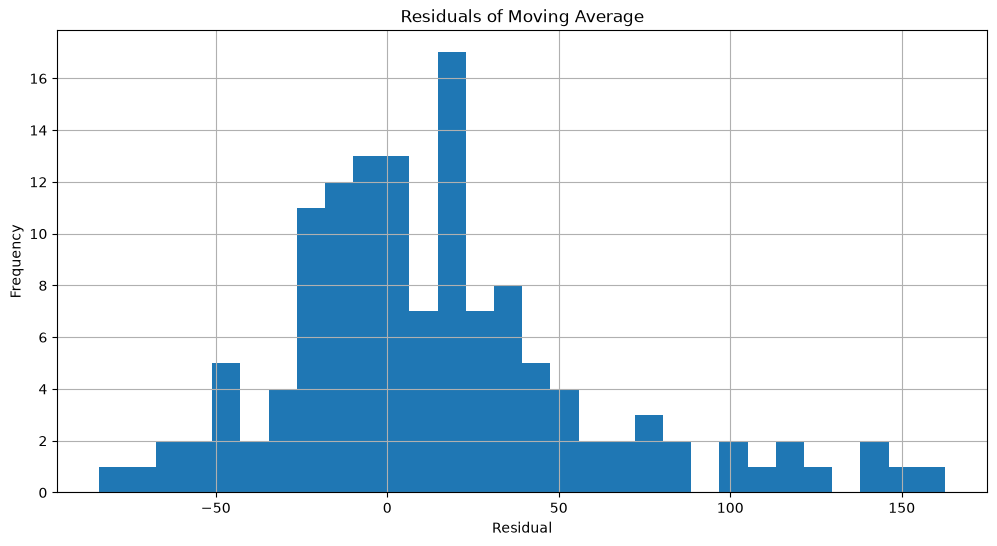

In [43]:
plt.figure(figsize=(12, 6))

plt.hist(residuals.dropna(), bins=30)

plt.title('Residuals of Moving Average')
plt.xlabel('Residual')
plt.ylabel('Frequency')

plt.grid(True)
plt.show()

In [44]:
percentile_90 = np.nanpercentile(abs(residuals), 90)

print('90th Percentile:', percentile_90)

90th Percentile: 77.64999999999998


In [45]:
high_residuals = residuals[abs(residuals) >= percentile_90]

high_residuals

Month
1955-07-01     99.583333
1955-08-01     78.083333
1956-07-01    101.000000
1956-08-01     88.166667
1957-07-01    114.583333
1957-08-01    111.416667
1958-07-01    114.666667
1958-08-01    125.500000
1959-07-01    143.083333
1959-08-01    149.583333
1960-06-01     81.750000
1960-07-01    162.583333
1960-08-01    142.666667
1960-11-01    -83.916667
dtype: float64

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این مرحله از روش <bdi dir="ltr">SMA (Simple Moving Average)</bdi> برای هموارسازی داده‌ها استفاده می‌کنیم. در این روش، میانگین مقادیر ۱۲ ماه متوالی رو محاسبه می‌کنیم تا نوسانات ماهانه کمتر بشه و روند کلی داده‌ها رو راحت‌تر مشاهده کنیم.

بعد از رسم نمودار، می‌بینیم که میانگین متحرک نسبت به نمودار اصلی هموارتره و روند صعودی تعداد مسافران رو به‌خوبی نشون می‌ده.

در ادامه، اختلاف بین مقادیر واقعی و میانگین متحرک رو محاسبه می‌کنیم که بهش <bdi dir="ltr">Residual</bdi> می‌گیم. با رسم نمودار <bdi dir="ltr">Histogram</bdi> متوجه می‌شیم که بیشتر اختلاف‌ها در محدوده نزدیک به صفر قرار دارن، اما در بعضی ماه‌ها اختلاف قابل‌توجهی وجود داره.

در نهایت، با محاسبه صدک ۹۰، ماه‌هایی رو که اختلاف زیادی با میانگین متحرک دارن شناسایی می‌کنیم. مشاهده می‌کنیم که بیشتر این ماه‌ها مربوط به جولای و آگوست هستن که معمولاً تعداد مسافران در اون‌ها بیشتره.
</div>

In [47]:
from statsmodels.tsa.api import ExponentialSmoothing

In [49]:
exponential_model = ExponentialSmoothing(df['Passengers'])

fit = exponential_model.fit(smoothing_level=0.7)

fitted_values = fit.fittedvalues

C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


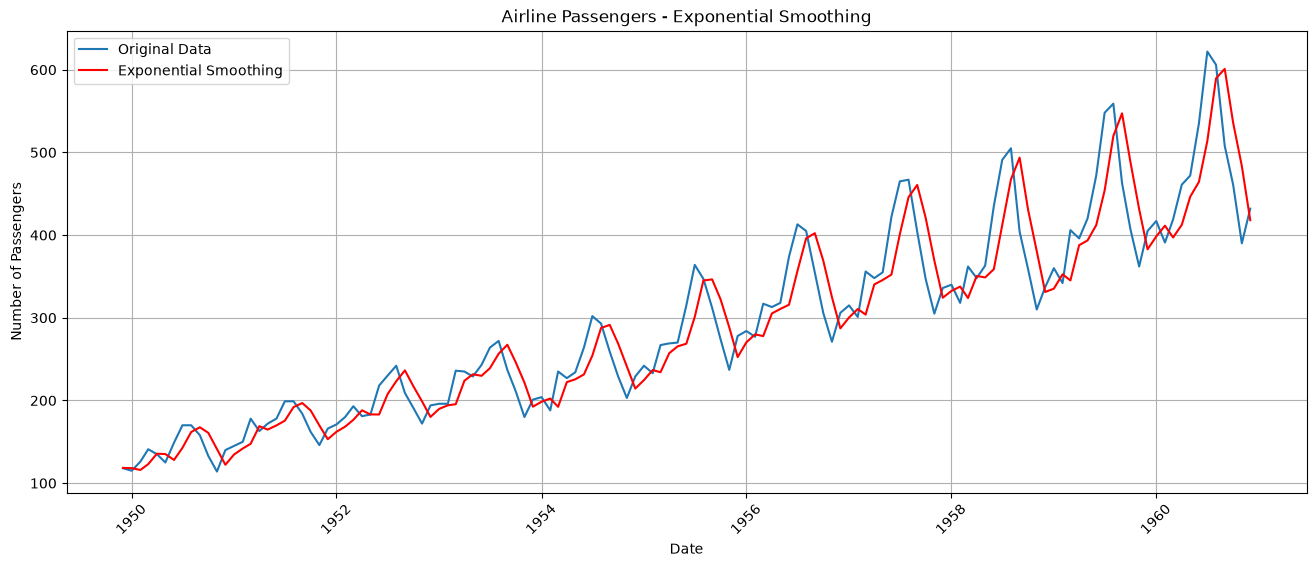

In [50]:
plt.figure(figsize=(16, 6))

plt.plot(df['Passengers'], label='Original Data')
plt.plot(fitted_values, color='red', label='Exponential Smoothing')

plt.title('Airline Passengers - Exponential Smoothing')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()

In [51]:
residuals_exp = df['Passengers'] - fitted_values

residuals_exp

Month
1949-12-01    -0.443989
1950-01-01    -3.133197
1950-02-01    10.060041
1950-03-01    18.018012
1950-04-01    -0.594596
                ...    
1960-08-01    16.460366
1960-09-01   -93.061890
1960-10-01   -74.918567
1960-11-01   -93.475570
1960-12-01    13.957329
Length: 133, dtype: float64

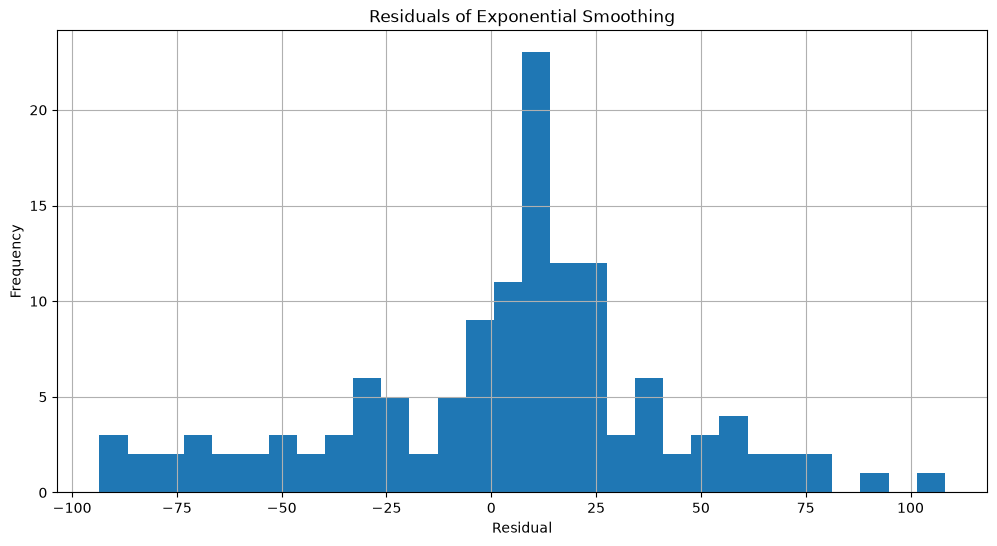

In [52]:
plt.figure(figsize=(12, 6))

plt.hist(residuals_exp.dropna(), bins=30)

plt.title('Residuals of Exponential Smoothing')
plt.xlabel('Residual')
plt.ylabel('Frequency')

plt.grid(True)
plt.show()

In [53]:
percentile_90_exp = np.nanpercentile(abs(residuals_exp), 90)

print('90th Percentile:', percentile_90_exp)

90th Percentile: 70.41589170190113


In [54]:
high_residuals_exp = residuals_exp[
    abs(residuals_exp) >= percentile_90_exp
]

high_residuals_exp

Month
1957-10-01    -73.993724
1958-06-01     76.268079
1958-07-01     78.880424
1958-09-01    -89.700762
1958-10-01    -71.910229
1958-11-01    -70.573069
1959-07-01     93.982702
1959-09-01    -84.241557
1959-10-01    -81.272467
1960-06-01     70.670733
1960-07-01    108.201220
1960-09-01    -93.061890
1960-10-01    -74.918567
1960-11-01    -93.475570
dtype: float64

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این مرحله از روش <bdi dir="ltr">Exponential Smoothing</bdi> برای هموارسازی داده‌ها استفاده می‌کنیم. تفاوت این روش با <bdi dir="ltr">SMA</bdi> اینه که در اینجا به داده‌های جدیدتر وزن بیشتری داده می‌شه و تأثیر داده‌های قدیمی‌تر به‌تدریج کاهش پیدا می‌کنه.

بعد از رسم نمودار، می‌بینیم که خط هموارشده نسبت به داده‌های اصلی نوسانات کمتری داره و در عین حال روند صعودی و الگوی فصلی داده‌ها همچنان قابل مشاهده هست.

در ادامه، اختلاف بین مقادیر واقعی و مقادیر هموارشده رو محاسبه می‌کنیم و با رسم نمودار <bdi dir="ltr">Histogram</bdi> توزیع این اختلاف‌ها رو بررسی می‌کنیم. در نهایت با محاسبه صدک ۹۰، ماه‌هایی رو که اختلاف زیادی با مقادیر هموارشده دارن شناسایی می‌کنیم. مشاهده می‌کنیم که بیشتر این اختلاف‌های بزرگ در سال‌های پایانی داده‌ها اتفاق افتادن.
</div>

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در نهایت با مقایسه دو روش <bdi dir="ltr">SMA</bdi> و <bdi dir="ltr">Exponential Smoothing</bdi> متوجه می‌شیم که روش دوم در نمودار ما بهتر تونسته تغییرات داده‌های اصلی رو دنبال کنه. همچنین در هر دو روش، روند صعودی تعداد مسافران در طول سال‌ها و الگوی فصلی داده‌ها همچنان قابل مشاهده هست. بنابراین می‌تونیم نتیجه بگیریم که هموارسازی باعث شده نوسانات کوتاه‌مدت کمتر بشن و بررسی روند کلی داده‌ها راحت‌تر انجام بشه.
</div>

In [56]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(
    df['Passengers'],
    trend='add',
    seasonal='mul',
    seasonal_periods=12
)

hw_fit = hw_model.fit()

hw_fitted_values = hw_fit.fittedvalues

C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


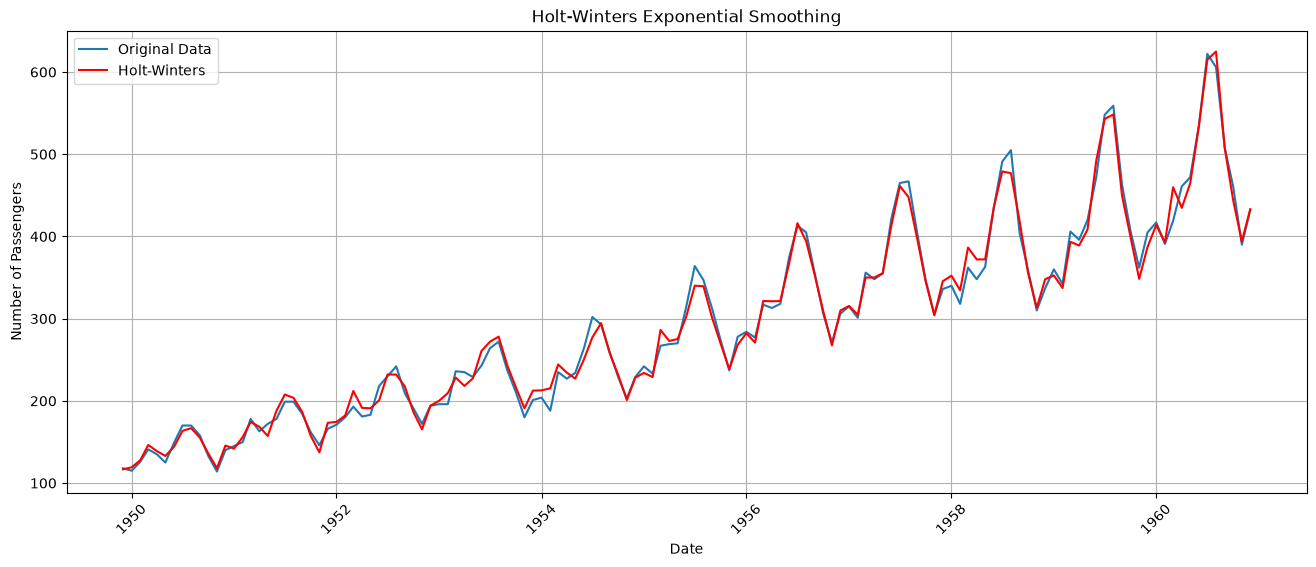

In [57]:
plt.figure(figsize=(16, 6))

plt.plot(df['Passengers'], label='Original Data')
plt.plot(
    hw_fitted_values,
    color='red',
    label='Holt-Winters'
)

plt.title('Holt-Winters Exponential Smoothing')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()

In [58]:
residuals_hw = df['Passengers'] - hw_fitted_values

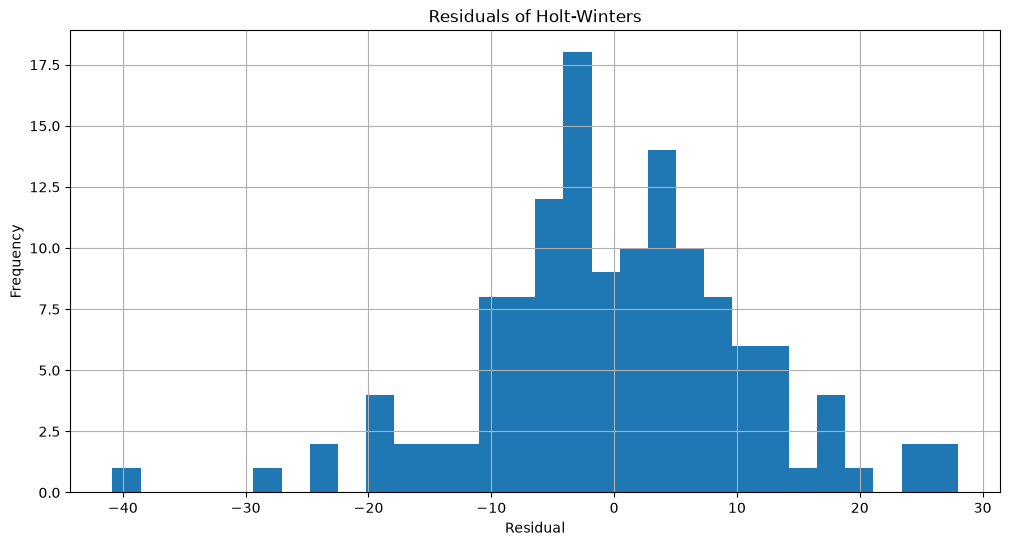

In [59]:
plt.figure(figsize=(12, 6))

plt.hist(residuals_hw.dropna(), bins=30)

plt.title('Residuals of Holt-Winters')
plt.xlabel('Residual')
plt.ylabel('Frequency')

plt.grid(True)
plt.show()

In [60]:
percentile_90_hw = np.nanpercentile(abs(residuals_hw), 90)

print('90th Percentile:', percentile_90_hw)

90th Percentile: 17.776888919200246


In [61]:
high_residuals_hw = residuals_hw[
    abs(residuals_hw) >= percentile_90_hw
]

high_residuals_hw

Month
1952-03-01   -19.045948
1953-06-01   -17.793934
1954-02-01   -27.298765
1954-07-01    24.812975
1955-03-01   -19.305218
1955-07-01    23.863104
1957-08-01    19.105418
1958-03-01   -24.479672
1958-04-01   -24.099984
1958-08-01    27.990802
1959-06-01   -19.949945
1960-03-01   -40.846246
1960-04-01    26.207587
1960-08-01   -18.915582
dtype: float64

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
با مقایسه سه روش <bdi dir="ltr">SMA</bdi>، <bdi dir="ltr">Exponential Smoothing</bdi> و <bdi dir="ltr">Holt-Winters</bdi> متوجه شدیم که روش Holt-Winters برای هموارسازی داده‌های ما نتیجه بهتری داشته. برای بررسی این موضوع، اختلاف مقادیر واقعی و مقادیر هموارشده رو محاسبه کردیم که بهش <bdi dir="ltr">Residual</bdi> می‌گیم، سپس نمودار هیستوگرام رو رسم کردیم و با محاسبه صدک ۹۰، ماه‌هایی رو که اختلاف زیادی داشتن شناسایی کردیم. مشاهده کردیم که اختلاف مقادیر در روش Holt-Winters به‌مراتب کمتر از دو روش دیگه بوده.

تفاوت این سه روش هم در نحوه محاسبه‌شونه؛ در روش <bdi dir="ltr">SMA</bdi> به تمام ماه‌های داخل پنجره وزن یکسانی داده می‌شه، اما در روش <bdi dir="ltr">Exponential Smoothing</bdi> به ماه‌های جدیدتر وزن بیشتری داده می‌شه و تأثیر ماه‌های قدیمی‌تر به‌تدریج کاهش پیدا می‌کنه. در روش <bdi dir="ltr">Holt-Winters</bdi> هم علاوه بر سطح داده‌ها، روند صعودی و الگوی فصلی به‌صورت جداگانه در مدل در نظر گرفته می‌شن. به همین دلیل این روش برای دیتاست ما که هم روند صعودی و هم الگوی فصلی داره، مناسب‌تر بوده.
</div>

In [62]:
train = df['Passengers'][:-12]
test = df['Passengers'][-12:]

In [63]:
print('Train:', train.shape)
print('Test:', test.shape)

print('Train Period:', train.index.min(), 'to', train.index.max())
print('Test Period:', test.index.min(), 'to', test.index.max())

Train: (121,)
Test: (12,)
Train Period: 1949-12-01 00:00:00 to 1959-12-01 00:00:00
Test Period: 1960-01-01 00:00:00 to 1960-12-01 00:00:00


In [64]:
hw_train_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='mul',
    seasonal_periods=12
)

hw_train_fit = hw_train_model.fit()

C:\Users\User\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [65]:
forecast = hw_train_fit.forecast(12)

forecast

1960-01-01    417.023365
1960-02-01    393.793684
1960-03-01    462.148484
1960-04-01    448.077385
1960-05-01    471.286680
1960-06-01    538.641685
1960-07-01    622.941689
1960-08-01    631.200991
1960-09-01    516.259345
1960-10-01    450.858507
1960-11-01    395.511293
1960-12-01    423.577411
Freq: MS, dtype: float64

In [66]:
comparison = pd.DataFrame({
    'Actual': test,
    'Forecast': forecast
})

comparison

,Actual,Forecast
1960-01-01,417,417.023365
1960-02-01,391,393.793684
1960-03-01,419,462.148484
1960-04-01,461,448.077385
1960-05-01,472,471.286680
1960-06-01,535,538.641685
1960-07-01,622,622.941689
1960-08-01,606,631.200991
1960-09-01,508,516.259345
1960-10-01,461,450.858507


<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
در این مرحله با استفاده از مدل <bdi dir="ltr">Holt-Winters</bdi>، قصد داریم مقادیر آینده سری زمانی خود را پیش‌بینی کنیم. ابتدا مدل را با استفاده از داده‌های سال‌های ۱۹۴۹ تا ۱۹۵۹ آموزش می‌دهیم و سپس از آن برای پیش‌بینی تعداد مسافران در سال ۱۹۶۰ استفاده می‌کنیم.

در ادامه، مقادیر پیش‌بینی‌شده را با داده‌های واقعی سال ۱۹۶۰ مقایسه می‌کنیم. با بررسی این مقادیر متوجه می‌شویم که پیش‌بینی مدل در بیشتر ماه‌ها به مقدار واقعی نزدیک بوده است. بنابراین می‌توان نتیجه گرفت که مدل عملکرد خوبی در پیش‌بینی داده‌های این بازه داشته است.
</div>

<div dir="rtl" style="
    background-color: #f5f7fb;
    border-right: 4px solid #6487c5;
    border-radius: 8px;
    padding: 18px 22px;
    color: #344054;
    font-size: 15px;
    line-height: 2.2;
    text-align: right;
">
ما در این تحلیل به این نتیجه رسیدیم که تعداد مسافران دارای الگوی فصلی واضح و مشخصی است و در کنار آن، در طول زمان یک روند صعودی کلی نیز دارد. با استفاده از سه روش هموارسازی، یعنی <bdi dir="ltr">Moving Average</bdi>، <bdi dir="ltr">Exponential Smoothing</bdi> و <bdi dir="ltr">Holt-Winters</bdi>، عملکرد این روش‌ها را بررسی و با یکدیگر مقایسه کردیم. با توجه به نتایج به دست آمده، روش <bdi dir="ltr">Holt-Winters</bdi> در هموارسازی داده‌ها و کاهش نوسانات، عملکرد بهتری نسبت به دو روش دیگر داشت.

در ادامه، با استفاده از مدل <bdi dir="ltr">Holt-Winters</bdi> و قابلیت <bdi dir="ltr">Forecast</bdi> آن، مقادیر آینده تعداد مسافران را پیش‌بینی کردیم و با مقایسه مقادیر پیش‌بینی‌شده و داده‌های واقعی، به نتایج قابل قبولی رسیدیم.
</div>